# Bài 6 (Trang 45) - Groceries Dataset
## Câu 3: c) Vẽ biểu đồ so sánh thời gian xử lý của hai thuật toán

**Sinh viên:** Trần Đình Võ - **MSSV:** 6451071088

In [1]:
HO_TEN = "Trần Đình Võ"
MSSV = "6451071088"
print(f"Họ tên: {HO_TEN} - MSSV: {MSSV}")

Họ tên: Trần Đình Võ - MSSV: 6451071088


### Import thư viện và đọc dữ liệu

In [2]:
import time
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, fpgrowth
%matplotlib inline

with open("../Dataset/groceries.csv", encoding="utf-8") as f:
    transactions = [line.strip().split(",") for line in f if line.strip()]

te = TransactionEncoder()
te_ary = te.fit(transactions).transform(transactions)
df = pd.DataFrame(te_ary, columns=te.columns_)
print("Số giao dịch:", df.shape[0], "- Số items:", df.shape[1])

# Thí nghiệm 1: min_sup = 0.01 -> 0.1 (bước 0.01)
supports = [round(0.01 * i, 2) for i in range(1, 11)]
# Thí nghiệm 2: min_sup rất nhỏ = 0.03% -> 0.1%
# (0.01%, 0.02% tương ứng support count 1-2 giao dịch -> số tập phổ biến bùng nổ tổ hợp, không chạy được)
supports_small = [0.0003, 0.0004, 0.0005, 0.0007, 0.001]


def benchmark(algo, sups):
    times, counts = [], []
    for s in sups:
        start = time.time()
        fi = algo(df, min_support=s, use_colnames=True)
        times.append(time.time() - start)
        counts.append(len(fi))
    return pd.DataFrame({"min_sup": sups, "so_tap_pho_bien": counts,
                         "thoi_gian_s": [round(t, 4) for t in times]})

Số giao dịch: 9835 - Số items: 169


### Các bước xử lý của câu 1 → 2 (chuẩn bị dữ liệu)

In [3]:
apriori_result = benchmark(apriori, supports)
apriori_result_small = benchmark(apriori, supports_small)

fp_result = benchmark(fpgrowth, supports)
fp_result_small = benchmark(fpgrowth, supports_small)

### Câu 3: c) Vẽ biểu đồ so sánh thời gian xử lý của hai thuật toán

In [4]:
compare = pd.concat([apriori_result, apriori_result_small]).rename(columns={"thoi_gian_s": "apriori_s"})
compare["fpgrowth_s"] = pd.concat([fp_result, fp_result_small])["thoi_gian_s"].values
compare.sort_values("min_sup").reset_index(drop=True)

,min_sup,so_tap_pho_bien,apriori_s,fpgrowth_s
0,0.0003,166682,34.6123,3.6666
1,0.0004,80388,15.3718,2.3351
2,0.0005,49580,8.9002,1.7539
3,0.0007,25570,5.0130,1.1795
4,0.0010,13492,2.6901,0.9441
5,0.0100,333,0.1474,0.1919
6,0.0200,122,0.0584,0.2132
7,0.0300,63,0.0321,0.1017
8,0.0400,41,0.0194,0.1125
9,0.0500,31,0.0177,0.0940


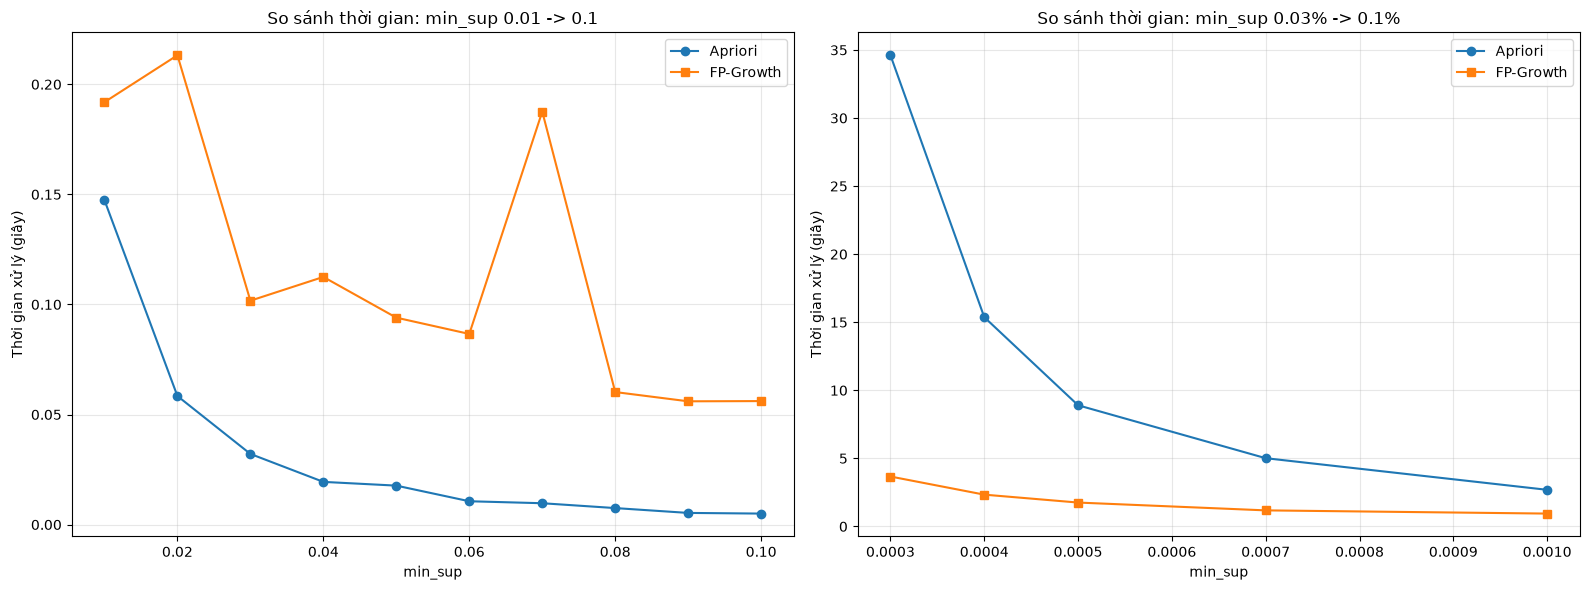

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, a, f, title in [(axes[0], apriori_result, fp_result, "min_sup 0.01 -> 0.1"),
                        (axes[1], apriori_result_small, fp_result_small, "min_sup 0.03% -> 0.1%")]:
    ax.plot(a["min_sup"], a["thoi_gian_s"], marker="o", label="Apriori")
    ax.plot(f["min_sup"], f["thoi_gian_s"], marker="s", label="FP-Growth")
    ax.set_xlabel("min_sup")
    ax.set_ylabel("Thời gian xử lý (giây)")
    ax.set_title("So sánh thời gian: " + title)
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Nhận xét
- Với min_sup lớn (0.01-0.1), số tập phổ biến ít, Apriori của mlxtend (vector hóa bằng numpy) chạy rất nhanh, thậm chí nhanh hơn FP-Growth vì chi phí xây cây FP không đáng kể so với số ứng viên ít.
- Với min_sup rất nhỏ (0.03%-0.1%), số tập phổ biến bùng nổ, Apriori phải sinh và đếm rất nhiều tập ứng viên ở mỗi mức nên thời gian tăng rất nhanh; FP-Growth nén dữ liệu thành cây FP, không sinh ứng viên, chỉ duyệt dữ liệu 2 lần nên nhanh hơn nhiều lần.
- Kết luận: FP-Growth hiệu quả hơn khi dữ liệu lớn và ngưỡng min_sup thấp.